# 06 - Decision Tree Classification

Part of the **Data Science Learning** project. Explanations, comments, and notebook messages are in English.

## Learning objectives
Train a decision tree and inspect how depth affects overfitting.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes, make_blobs
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

In [2]:
dataset = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(dataset.data, dataset.target, test_size=0.2, random_state=RANDOM_STATE, stratify=dataset.target)

## Compare tree depths

,max_depth,train_accuracy,test_accuracy
0,1,0.923077,0.921053
1,2,0.958242,0.894737
2,3,0.975824,0.938596
3,4,0.986813,0.938596
4,5,0.993407,0.921053
5,7,1.000000,0.912281
6,10,1.000000,0.912281
7,None,1.000000,0.912281


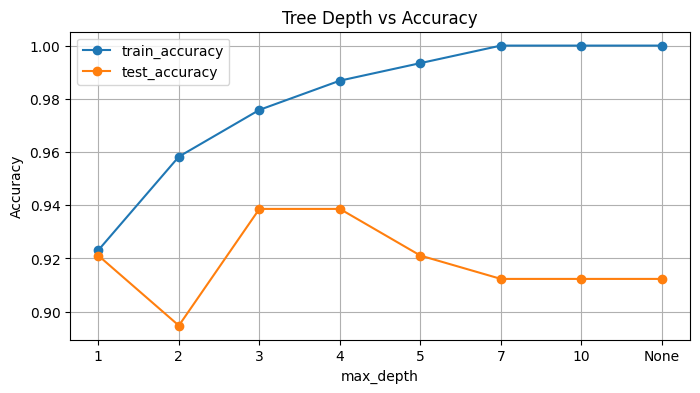

In [3]:
from sklearn.tree import DecisionTreeClassifier

rows = []
for depth in [1, 2, 3, 4, 5, 7, 10, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    rows.append({"max_depth": str(depth), "train_accuracy": model.score(X_train, y_train), "test_accuracy": model.score(X_test, y_test)})

results = pd.DataFrame(rows)
display(results)
results.set_index("max_depth").plot(marker="o", figsize=(8, 4), title="Tree Depth vs Accuracy")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

## Feature importance

              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



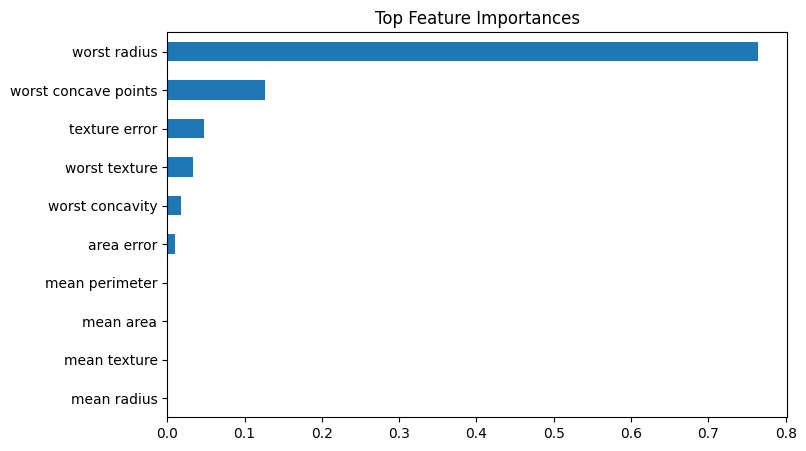

In [4]:
model = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(classification_report(y_test, pred, target_names=dataset.target_names))
pd.Series(model.feature_importances_, index=dataset.feature_names).nlargest(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top Feature Importances")
plt.show()

## Exercises
1. Try `min_samples_leaf`.
2. Compare Gini and entropy criteria.
3. Explain the train/test accuracy gap.